In [8]:
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")                      # lets the script run without a screen
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, make_scorer)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
PATH = r"C:\Users\BIDISHA\Downloads\archive.zip"
SEED = 42
os.makedirs("results", exist_ok=True)


def title(text):
    print("\n" + "=" * 70 + f"\n{text}\n" + "=" * 70)

In [12]:
#CLEAN THE DATA

title("CLEAN THE DATA")
df = pd.read_csv(PATH)
print("Rows loaded:", len(df))

df = df.rename(columns={"thalch": "thalach", "num": "target"})
df = df.drop(columns=["id", "dataset"])      # row number + hospital name: not medical info

# Cholesterol = 0 and blood pressure = 0 are impossible -> treat as missing
for col in ["chol", "trestbps"]:
    print(f"{col}: {(df[col] == 0).sum()} impossible zeros set to missing")
    df.loc[df[col] == 0, col] = np.nan

df = df.drop_duplicates()

# Drop columns that are mostly empty
missing_pct = df.drop(columns="target").isnull().mean() * 100
print("\nMissing % per column:\n", missing_pct.round(1).to_string())
too_empty = missing_pct[missing_pct > 50].index.tolist()
df = df.drop(columns=too_empty)
print("Dropped (over 50% missing):", too_empty)

# Target: 0 = no heart disease, 1 = heart disease
df["target"] = (df["target"] > 0).astype(int)

# Text -> numbers
df["sex"] = (df["sex"] == "Male").astype(int)
for col in ["fbs", "exang"]:
    df[col] = df[col].map({True: 1, False: 0, "True": 1, "False": 0})   # stays NaN if unknown
for col in ["cp", "restecg", "slope"]:
    df[col] = df[col].fillna("unknown")      # "unknown" becomes its own category
df = pd.get_dummies(df, columns=["cp", "restecg", "slope"], dtype=int)
df.columns = [c.replace(" ", "_").replace("-", "_") for c in df.columns]
# Remove one column from each group so they are not perfect copies of each other
df = df.drop(columns=["cp_asymptomatic", "restecg_normal", "slope_unknown"])

print("Shape after cleaning:", df.shape)
print("Note: remaining gaps in numeric columns are filled later, AFTER the split,")
print("      using only training data (this avoids 'data leakage').")



CLEAN THE DATA
Rows loaded: 920
chol: 172 impossible zeros set to missing
trestbps: 1 impossible zeros set to missing

Missing % per column:
 age          0.0
sex          0.0
cp           0.0
trestbps     6.5
chol        21.9
fbs          9.8
restecg      0.2
thalach      6.0
exang        6.0
oldpeak      6.8
slope       33.4
ca          66.3
thal        52.7
Dropped (over 50% missing): ['ca', 'thal']
Shape after cleaning: (918, 18)
Note: remaining gaps in numeric columns are filled later, AFTER the split,
      using only training data (this avoids 'data leakage').


In [13]:
 # FEATURE ENGINEERING

title("FEATURE ENGINEERING")
max_hr = 220 - df["age"]                                   # rough max heart rate for age
df["hr_pct_of_max"] = df["thalach"] / max_hr               # how close to max heart rate
df["high_bp"] = (df["trestbps"] >= 140).astype(float).where(df["trestbps"].notna())
df["high_chol"] = (df["chol"] >= 240).astype(float).where(df["chol"].notna())
df["age_over_55"] = (df["age"] > 55).astype(int)
print("Added: hr_pct_of_max, high_bp, high_chol, age_over_55")

X = df.drop(columns="target")
y = df["target"]


FEATURE ENGINEERING
Added: hr_pct_of_max, high_bp, high_chol, age_over_55


In [15]:
#SPLIT THE DATA 

title("SPLIT THE DATA (80% train / 20% test, same disease ratio in both)")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Disease rate - train: %.1f%%, test: %.1f%%" % (y_train.mean() * 100, y_test.mean() * 100))

# A temporary filled-in copy of the training data, only for the checks below
imp = SimpleImputer(strategy="median").fit(X_train)
X_train_filled = pd.DataFrame(imp.transform(X_train), columns=X.columns, index=X_train.index)


SPLIT THE DATA (80% train / 20% test, same disease ratio in both)
Train: (734, 21)  Test: (184, 21)
Disease rate - train: 55.3%, test: 55.4%


In [26]:
print("Columns in X:", X.columns.tolist())
print("Columns in X_train_filled:", X_train_filled.columns.tolist())

print("Missing columns:",
      list(set(X.columns) - set(X_train_filled.columns)))

Columns in X: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'cp_atypical_angina', 'cp_non_anginal', 'cp_typical_angina', 'restecg_lv_hypertrophy', 'restecg_st_t_abnormality', 'restecg_unknown', 'slope_downsloping', 'slope_flat', 'slope_upsloping', 'hr_pct_of_max', 'high_bp', 'high_chol', 'age_over_55']
Columns in X_train_filled: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'exang', 'oldpeak', 'cp_atypical_angina', 'cp_non_anginal', 'cp_typical_angina', 'restecg_lv_hypertrophy', 'restecg_st_t_abnormality', 'slope_downsloping', 'slope_flat', 'slope_upsloping', 'hr_pct_of_max', 'high_bp', 'high_chol', 'age_over_55']
Missing columns: ['thalach', 'restecg_unknown']



MULTICOLLINEARITY

Final VIF values (all should be under 10):
                  feature  VIF
                     age 2.88
                trestbps 2.80
             age_over_55 2.77
                 high_bp 2.73
              slope_flat 2.10
               high_chol 1.77
                    chol 1.77
                 oldpeak 1.70
         slope_upsloping 1.62
                   exang 1.60
       slope_downsloping 1.55
      cp_atypical_angina 1.43
           hr_pct_of_max 1.43
          cp_non_anginal 1.29
  restecg_lv_hypertrophy 1.21
restecg_st_t_abnormality 1.16
       cp_typical_angina 1.16
                     fbs 1.10
                     sex 1.10

Features kept: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'exang', 'oldpeak', 'cp_atypical_angina', 'cp_non_anginal', 'cp_typical_angina', 'restecg_lv_hypertrophy', 'restecg_st_t_abnormality', 'slope_downsloping', 'slope_flat', 'slope_upsloping', 'hr_pct_of_max', 'high_bp', 'high_chol', 'age_over_55']


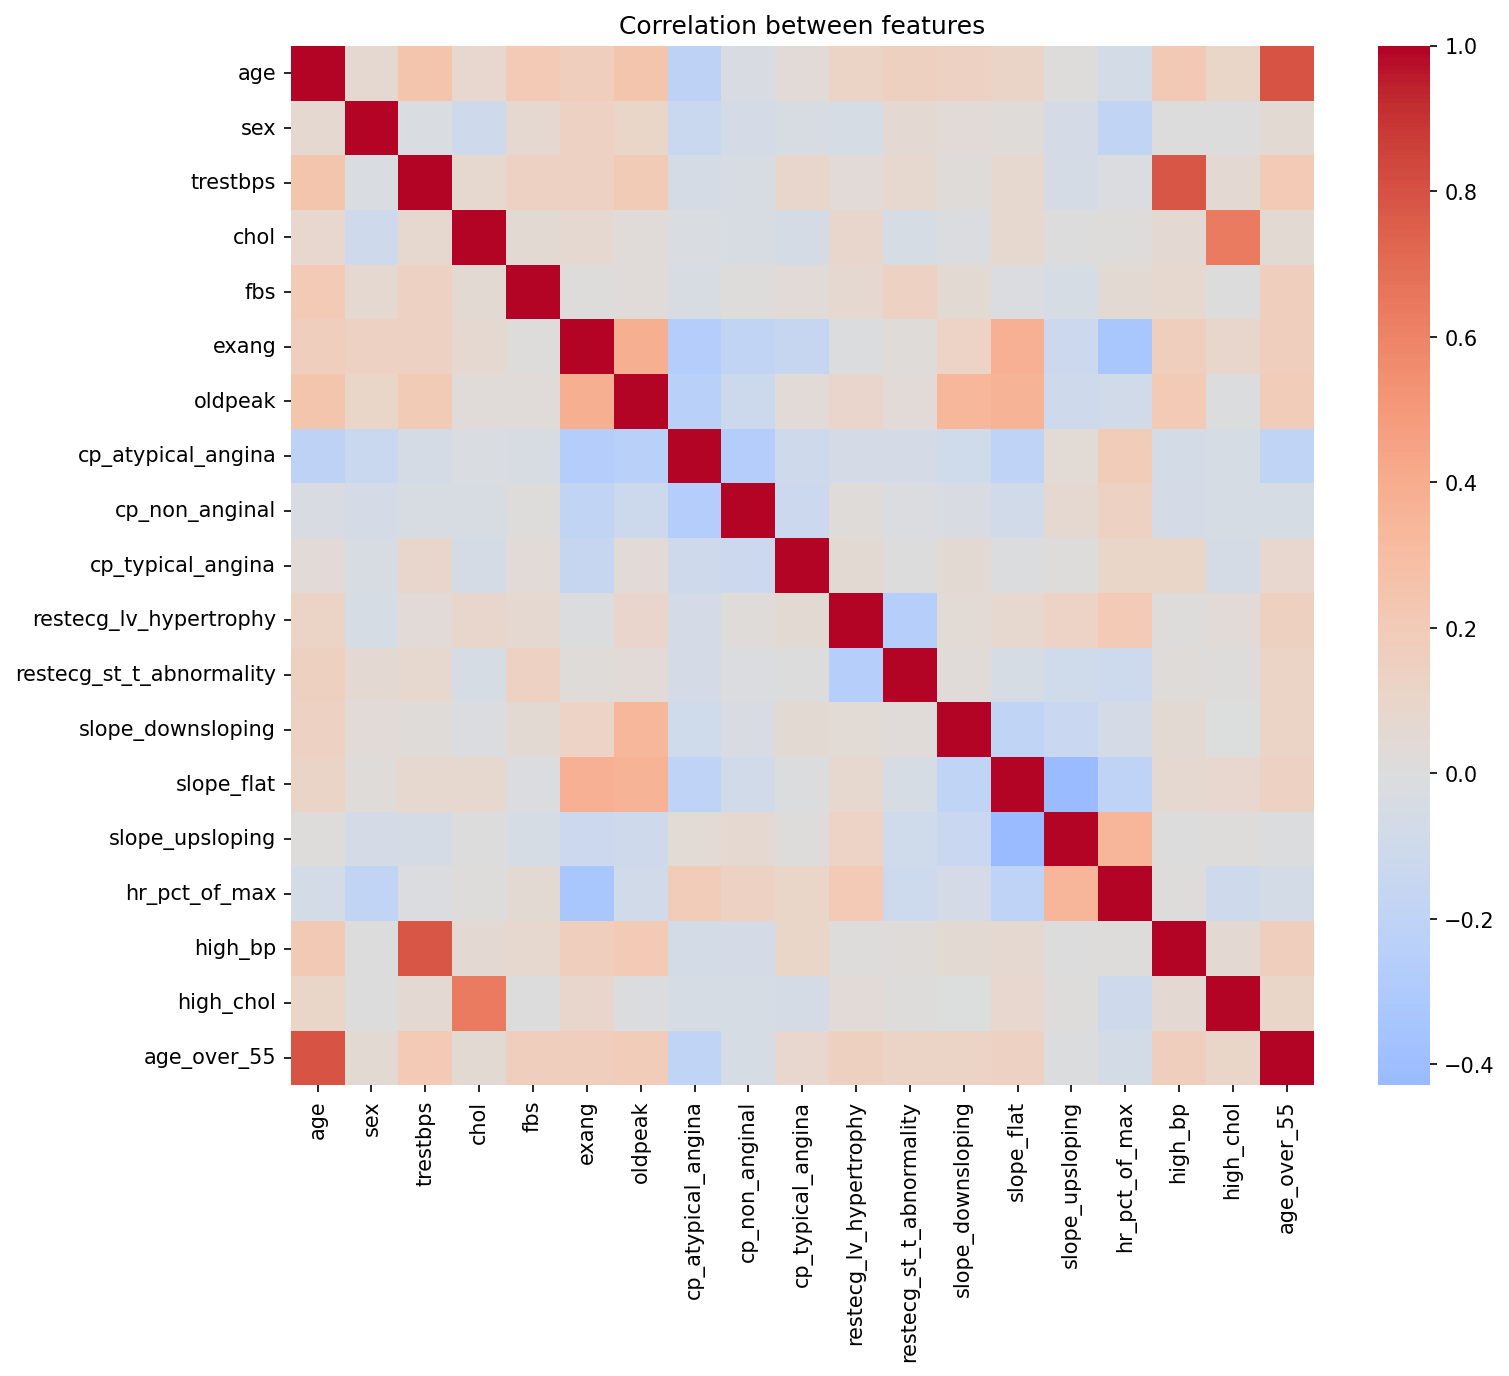

In [34]:
#CHECK MULTICOLLINEARITY

title("MULTICOLLINEARITY")
 
plt.figure(figsize=(11, 9))
sns.heatmap(X_train_filled.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between features")
plt.savefig("results/1_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.close()
 
 
def vif_table(data):
    """VIF: how well each column can be predicted from the others. Over 10 = problem."""
    rows = []
    for col in data.columns:
        others = data.drop(columns=col)
        r2 = LinearRegression().fit(others, data[col]).score(others, data[col])
        rows.append((col, 1 / (1 - r2) if r2 < 0.9999 else np.inf))
    return pd.DataFrame(rows, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)
 
 
keep = [col for col in X.columns if col in X_train_filled.columns]
while True:
    vif = vif_table(X_train_filled[keep])
    worst = vif.iloc[0]
    if worst["VIF"] <= 10:
        break
    print(f"Dropping '{worst['feature']}' (VIF = {worst['VIF']:.1f})")
    keep.remove(worst["feature"])
 
print("\nFinal VIF values (all should be under 10):\n", vif.round(2).to_string(index=False))
print("\nFeatures kept:", keep)
X_train, X_test, X_train_filled = X_train[keep], X_test[keep], X_train_filled[keep]

from IPython.display import display, Image

display(Image(filename="results/1_correlation_heatmap.png"))
 

In [29]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_train_filled:", X_train_filled.shape)

X_train: (734, 19)
X_test: (184, 19)
X_train_filled: (734, 19)


In [18]:
#MODELS

models = {
    "Logistic Regression": Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "Random Forest": Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=6,
                                         min_samples_leaf=3, random_state=SEED))]),
    "XGBoost": Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                subsample=0.9, colsample_bytree=0.9,
                                eval_metric="logloss", random_state=SEED))]),
}


IMPORTANT FEATURES

Top 8 Features (Random Forest):


,Importance
exang,0.146
cp_atypical_angina,0.132
hr_pct_of_max,0.121
oldpeak,0.119
age,0.101
sex,0.070
chol,0.065
slope_flat,0.057


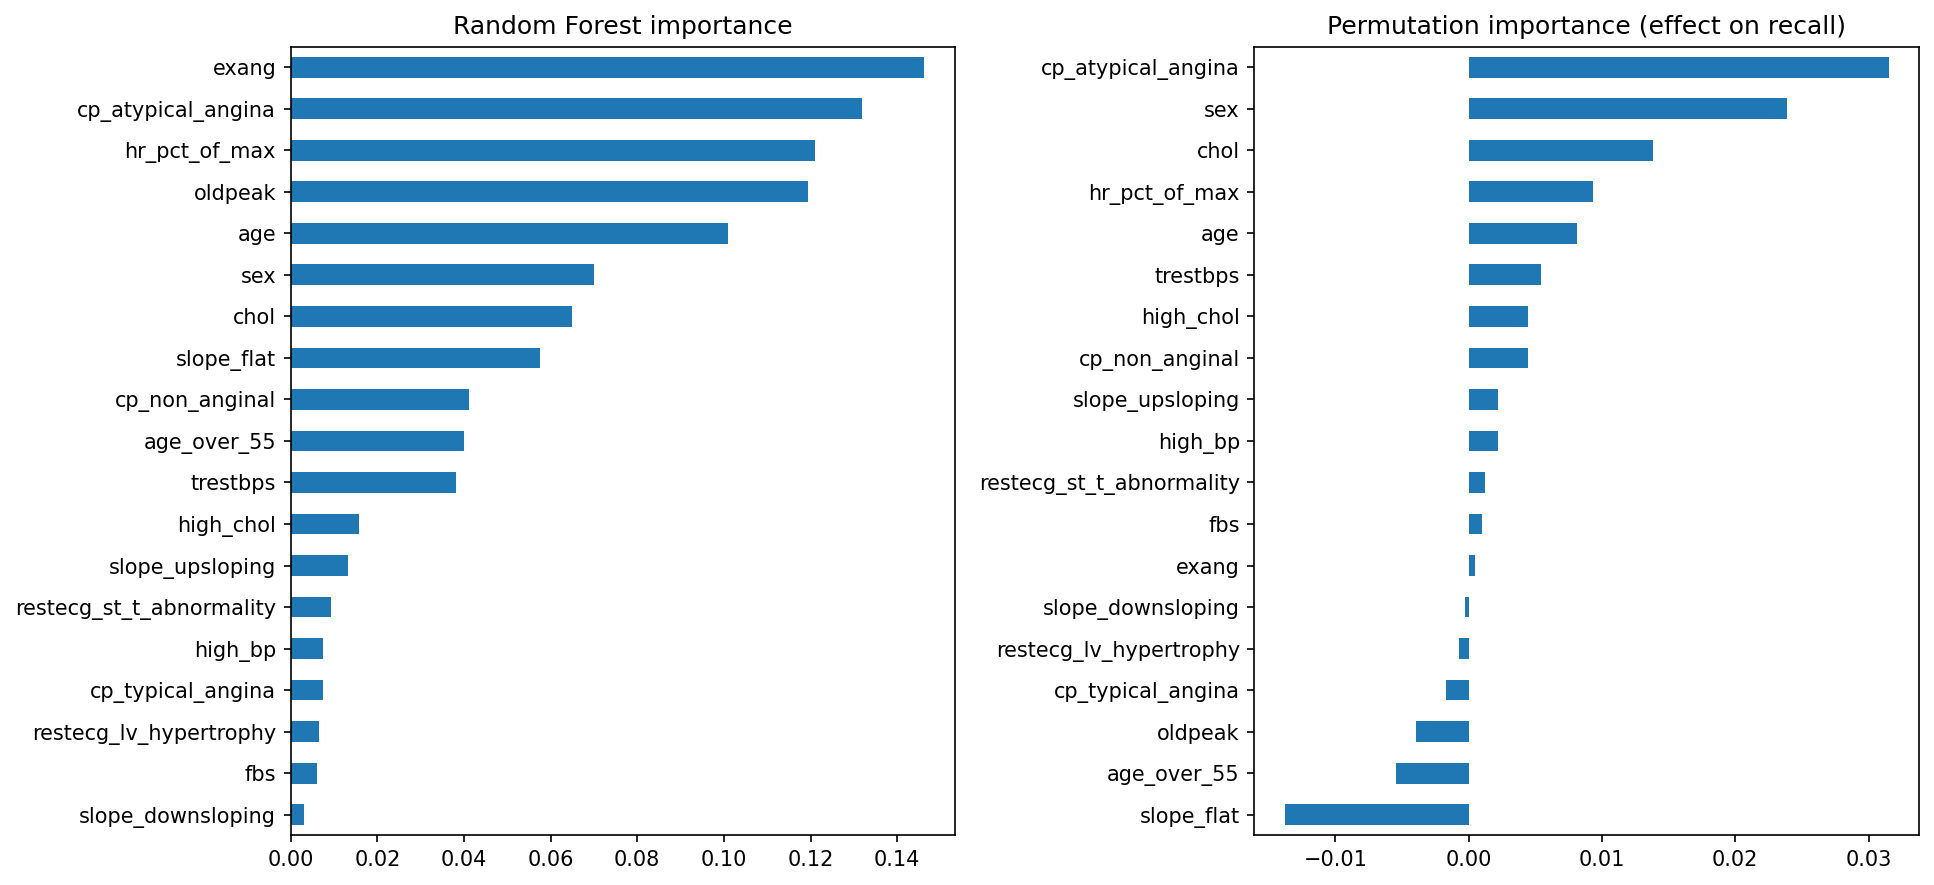

In [30]:
#FIND IMPORTANT FEATURES

title("IMPORTANT FEATURES")
rf_quick = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3,
                                  random_state=SEED).fit(X_train_filled, y_train)
built_in = pd.Series(rf_quick.feature_importances_, index=keep)
perm = permutation_importance(rf_quick, X_train_filled, y_train, n_repeats=10,
                              random_state=SEED, scoring="recall")
perm = pd.Series(perm.importances_mean, index=keep)
 
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
built_in.sort_values().plot(kind="barh", ax=axes[0], title="Random Forest importance")
perm.sort_values().plot(kind="barh", ax=axes[1], title="Permutation importance (effect on recall)")
plt.tight_layout()
plt.savefig("results/2_feature_importance.png", dpi=150, bbox_inches="tight")
plt.close()
top8 = built_in.sort_values(ascending=False).head(8).round(3)

print("\nTop 8 Features (Random Forest):")
display(top8.rename("Importance").to_frame())

from IPython.display import Image, display

display(Image(filename="results/2_feature_importance.png"))

In [31]:
#TRAIN THE MODELS

title("TRAIN LOGISTIC REGRESSION (baseline), RANDOM FOREST, XGBOOST")
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print("Trained:", name)


TRAIN LOGISTIC REGRESSION (baseline), RANDOM FOREST, XGBOOST
Trained: Logistic Regression
Trained: Random Forest
Trained: XGBoost



TEST RESULTS: accuracy, precision, recall, F1, confusion matrix

--- Logistic Regression ---
              precision    recall  f1-score   support

  No disease       0.80      0.74      0.77        82
     Disease       0.81      0.85      0.83       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184

Missed sick patients: 15 out of 102 | False alarms: 21 out of 82

--- Random Forest ---
              precision    recall  f1-score   support

  No disease       0.80      0.74      0.77        82
     Disease       0.81      0.85      0.83       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184

Missed sick patients: 15 out of 102 | False alarms: 21 out of 82

--- XGBoost ---
              precision    recall  f1-score   support

  No disease       0.82    

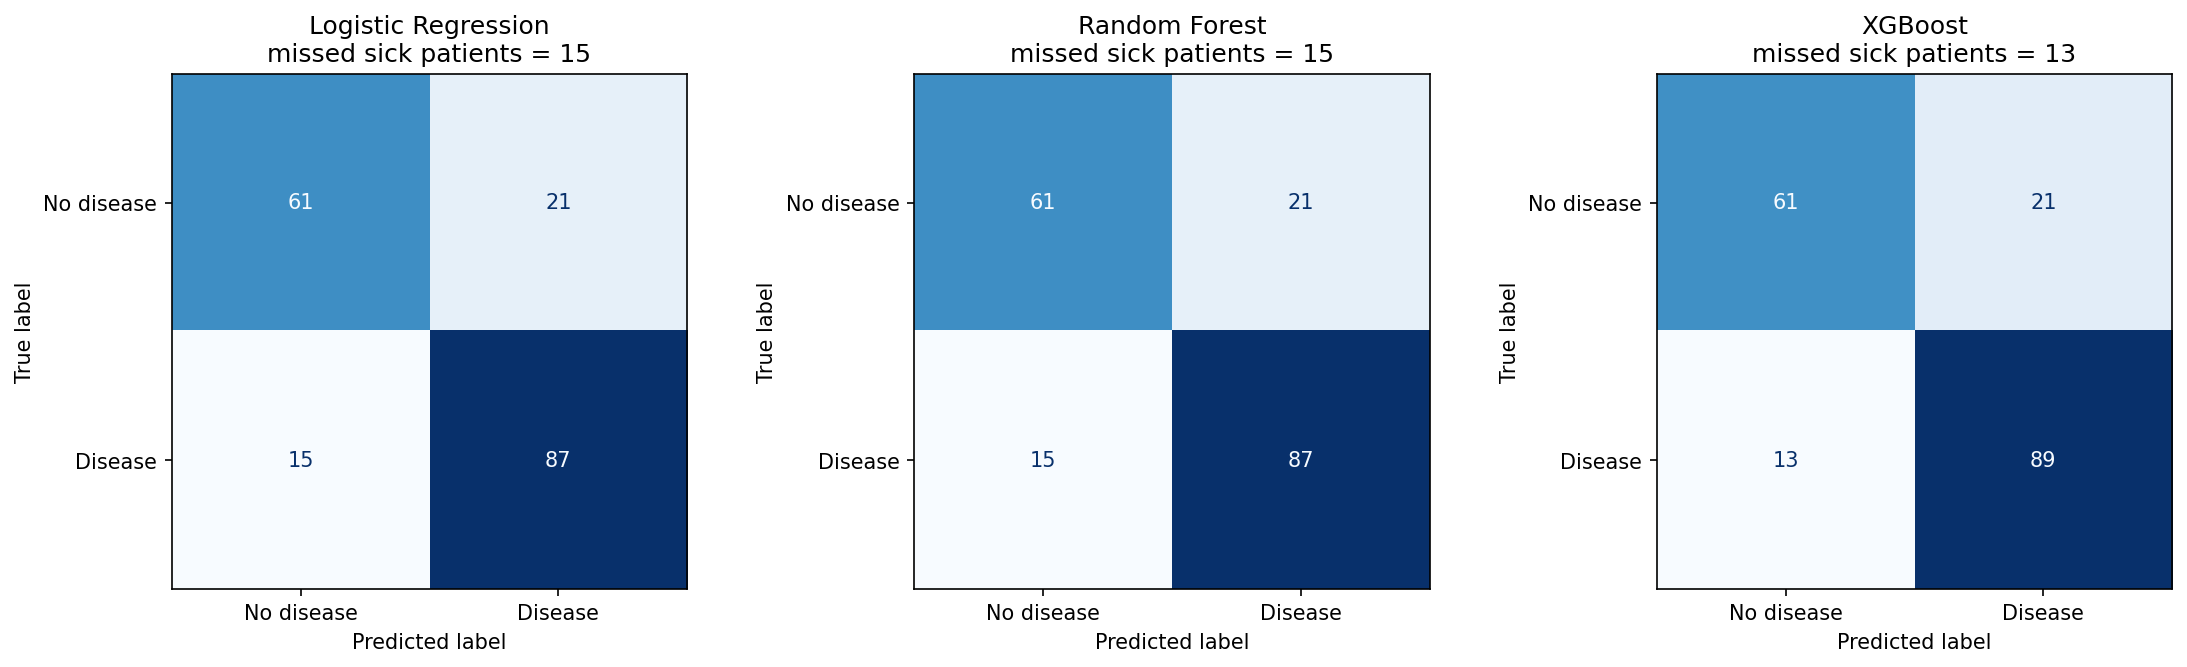

In [35]:
#EVALUATE ON THE TEST SET

title("TEST RESULTS: accuracy, precision, recall, F1, confusion matrix")
results, matrices = [], {}
for name, pipe in models.items():
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    matrices[name] = confusion_matrix(y_test, pred)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Missed sick patients (FN)": fn,
        "False alarms (FP)": fp,
    })
    print(f"\n--- {name} ---")
    print(classification_report(y_test, pred, target_names=["No disease", "Disease"]))
    print(f"Missed sick patients: {fn} out of {tp + fn} | False alarms: {fp} out of {tn + fp}")
 
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, cm) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nmissed sick patients = {cm[1, 0]}")
plt.tight_layout()
plt.savefig("results/3_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
 
test_table = pd.DataFrame(results).set_index("Model")

from IPython.display import display, Image

display(Image(filename="results/3_confusion_matrices.png"))

In [39]:
#CROSS VALIDATION


title("5-FOLD CROSS-VALIDATION (Training Data)")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2),
    "roc_auc": "roc_auc"
}

cv_rows = {}

for name, pipe in models.items():
    s = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring
    )

    cv_rows[name] = {
        f"CV {k}": s[f"test_{k}"].mean()
        for k in scoring
    }

    cv_rows[name].update({
        f"CV {k} std": s[f"test_{k}"].std()
        for k in ["accuracy", "recall"]
    })

cv_table = pd.DataFrame(cv_rows).T

display(
    cv_table.style
    .format("{:.3f}")
    .set_caption("5-Fold Cross-Validation Results")
    .set_properties(**{
        "text-align": "center",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "8px")
            ]
        }
    ])
)



5-FOLD CROSS-VALIDATION (Training Data)


,CV accuracy,CV precision,CV recall,CV f1,CV f2,CV roc_auc,CV accuracy std,CV recall std
Logistic Regression,0.798,0.808,0.837,0.822,0.831,0.871,0.036,0.019
Random Forest,0.797,0.801,0.847,0.823,0.837,0.867,0.051,0.032
XGBoost,0.785,0.795,0.828,0.811,0.820,0.863,0.044,0.016



MODEL COMPARISON
                     Accuracy  Precision  Recall     F1  ROC-AUC  Missed sick patients (FN)  CV accuracy  CV recall
Model                                                                                                              
Logistic Regression     0.804      0.806   0.853  0.829    0.906                         15        0.798      0.837
Random Forest           0.804      0.806   0.853  0.829    0.891                         15        0.797      0.847
XGBoost                 0.815      0.809   0.873  0.840    0.890                         13        0.785      0.828

Best model (highest cross-validated F2, which favours recall): Random Forest
Saved -> results/best_heart_model.joblib

Reminder: this is a learning project, not a medical diagnosis tool.


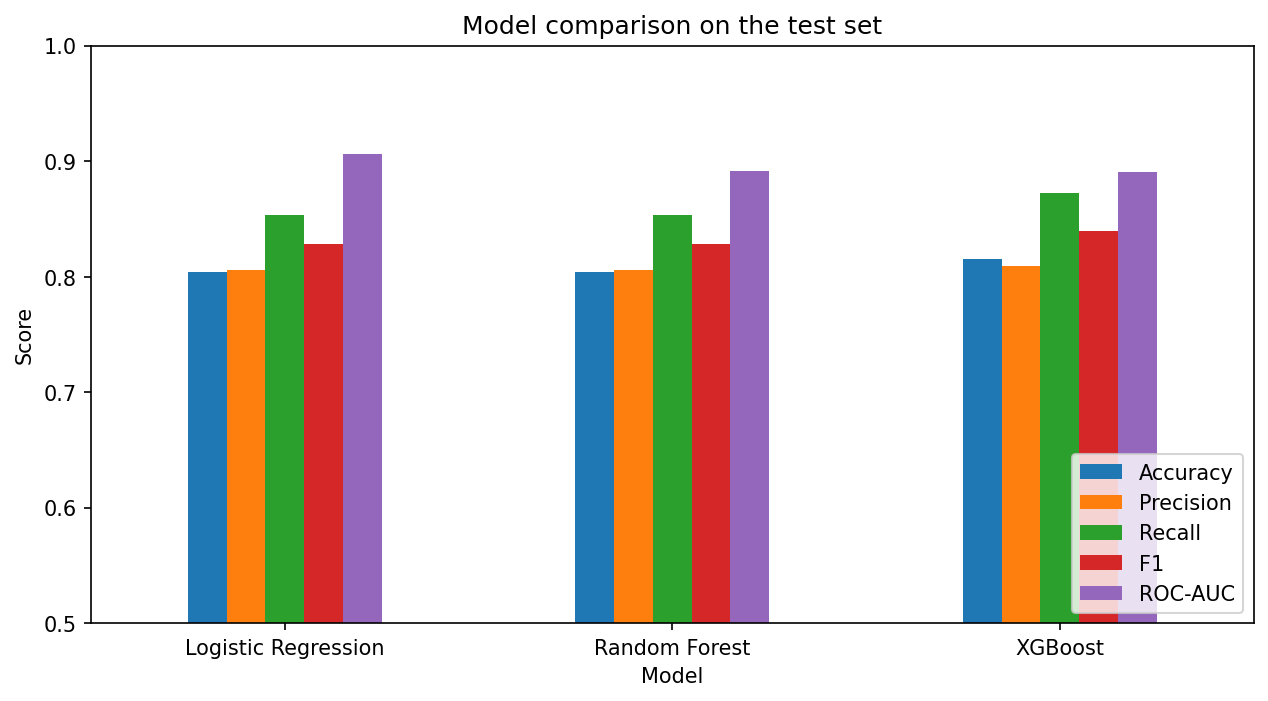

In [40]:
#COMPARISON

title("MODEL COMPARISON")
final = test_table.join(cv_table)
final.round(3).to_csv("results/model_comparison.csv")
print(final[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC",
             "Missed sick patients (FN)", "CV accuracy", "CV recall"]].round(3).to_string())
 
plot_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
final[plot_cols].plot(kind="bar", figsize=(10, 5), ylim=(0.5, 1.0), rot=0,
                      title="Model comparison on the test set")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.savefig("results/4_model_comparison.png", dpi=150, bbox_inches="tight")
plt.close()
 
# Best model = highest cross-validated F2
best = final["CV f2"].idxmax()
print(f"\nBest model (highest cross-validated F2, which favours recall): {best}")
joblib.dump({"model": models[best], "features": keep}, "results/best_heart_model.joblib")
print("Saved -> results/best_heart_model.joblib")
print("\nReminder: this is a learning project, not a medical diagnosis tool.")

from IPython.display import display, Image

display(Image(filename="results/4_model_comparison.png"))
 